In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
# ==========================================
# 1. Генерація реалістичних даних StreamPulse (Churn)
# ==========================================
np.random.seed(42)
n_users = 1500

df = pd.DataFrame({
    "age": np.random.randint(18, 65, size=n_users),
    "tenure_months": np.random.randint(1, 60, size=n_users),
    "monthly_watch_hours": np.round(
        np.random.gamma(shape=3.0, scale=8.0, size=n_users), 1
    ),
    "support_tickets": np.random.poisson(lam=1.2, size=n_users),
    "payment_delays": np.random.poisson(lam=0.5, size=n_users),
    "subscription_tier": np.random.choice(
        ["Basic", "Standard", "Premium"], size=n_users, p=[0.45, 0.35, 0.20]
    ),
    "contract_type": np.random.choice(
        ["Monthly", "Annual"], size=n_users, p=[0.70, 0.30]
    ),
})

# Імітуємо невелику кількість пропусків, щоб пайплайн відпрацював і імпутацію
df.loc[np.random.choice(df.index, 30, replace=False), "monthly_watch_hours"] = (
    np.nan
)
df.loc[np.random.choice(df.index, 20, replace=False), "subscription_tier"] = (
    np.nan
)

# Формуємо логічну ймовірність відтоку (Churn = 1)
logit = (
    -1.2
    - 0.03 * df["tenure_months"]
    - 0.04 * df["monthly_watch_hours"].fillna(24)
    + 0.45 * df["support_tickets"]
    + 0.65 * df["payment_delays"]
    + np.where(df["contract_type"] == "Monthly", 0.9, -0.8)
    + np.where(df["subscription_tier"] == "Basic", 0.4, -0.2)
)
prob_churn = 1 / (1 + np.exp(-logit))
df["churn"] = (np.random.rand(n_users) < prob_churn).astype(int)

X = df.drop("churn", axis=1)
y = df["churn"]

# Розділення на навчальну і тестову вибірки (80/20) зі стратифікацією
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [3]:
# ==========================================
# 2. Побудова Scikit-Learn Pipeline для препроцесингу
# ==========================================
numeric_features = [
    "age",
    "tenure_months",
    "monthly_watch_hours",
    "support_tickets",
    "payment_delays",
]
categorical_features = ["subscription_tier", "contract_type"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

In [4]:
# ==========================================
# 3. Навчання та порівняння моделей у пайплайнах
# ==========================================
models = {
    "Logistic Regression": LogisticRegression(
        random_state=42, max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        class_weight="balanced",
    ),
}

results = {}

for name, classifier in models.items():
    clf_pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("classifier", classifier)]
    )
    clf_pipeline.fit(X_train, y_train)

    y_pred = clf_pipeline.predict(X_test)
    y_proba = clf_pipeline.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_proba)

    results[name] = {
        "pipeline": clf_pipeline,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "roc_auc": roc_auc,
    }

    print(f"=== {name} ===")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(classification_report(y_test, y_pred, digits=4))

# Вибираємо найкращу модель за ROC-AUC
best_model_name = max(results, key=lambda k: results[k]["roc_auc"])
best_res = results[best_model_name]
print(
    f"Найкраща модель для StreamPulse: {best_model_name} (ROC-AUC = {best_res['roc_auc']:.4f})"
)

=== Logistic Regression ===
ROC-AUC: 0.8385
              precision    recall  f1-score   support

           0     0.9464    0.6824    0.7930       233
           1     0.4394    0.8657    0.5829        67

    accuracy                         0.7233       300
   macro avg     0.6929    0.7740    0.6880       300
weighted avg     0.8332    0.7233    0.7461       300

=== Random Forest ===
ROC-AUC: 0.7857
              precision    recall  f1-score   support

           0     0.8851    0.6609    0.7568       233
           1     0.3730    0.7015    0.4870        67

    accuracy                         0.6700       300
   macro avg     0.6290    0.6812    0.6219       300
weighted avg     0.7707    0.6700    0.6965       300

Найкраща модель для StreamPulse: Logistic Regression (ROC-AUC = 0.8385)


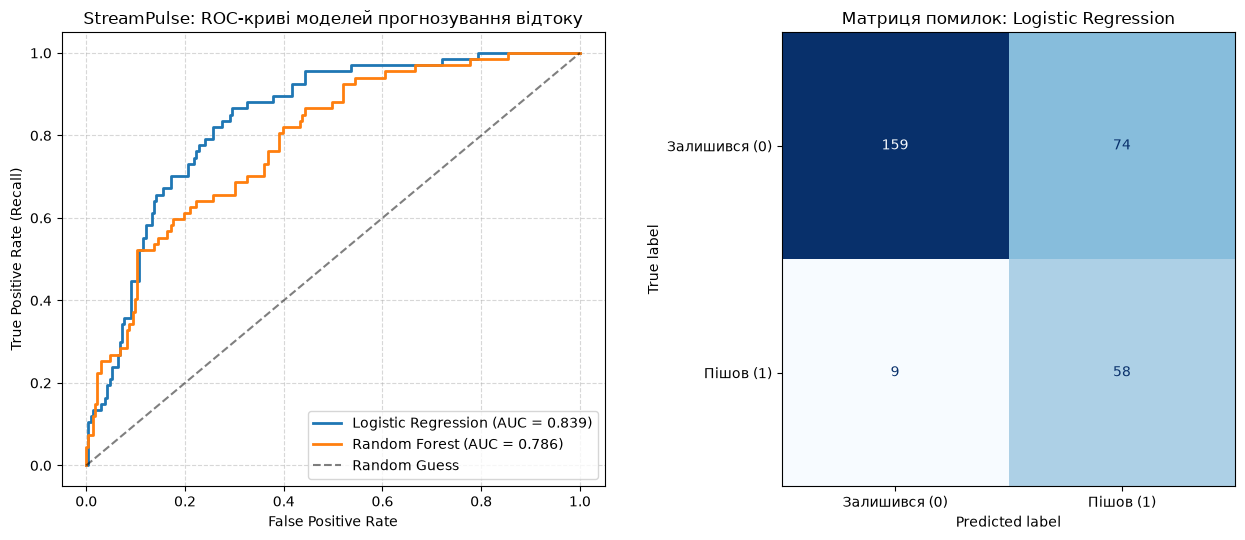

In [5]:
# ==========================================
# 4. Візуалізація: ROC-криві та Confusion Matrix
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Графік 1: ROC-криві обох моделей
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0].plot(
        fpr, tpr, linewidth=2, label=f"{name} (AUC = {res['roc_auc']:.3f})"
    )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess")
axes[0].set_title("StreamPulse: ROC-криві моделей прогнозування відтоку")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Графік 2: Матриця помилок для найкращої моделі
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_res["y_pred"],
    display_labels=["Залишився (0)", "Пішов (1)"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title(f"Матриця помилок: {best_model_name}")

plt.tight_layout()
plt.savefig("streampulse_churn_results.png", dpi=300)
plt.show()